**ESPECTRO-NCh2369of2025**

 ESPECTRO SÍSMICO — NCh2369:2025
 Zona Sísmica : 3 -> A0 = 0.40 g | Ar = 0.56 g (5.4917 m/s²)
 Tipo Suelo   : C -> S=1.05, r=4.5, T0=0.4 s, p=1.5, q=3.0, T1=0.35 s
 Categoría    : II (I = 1.00) | R = 5.0 | xi = 0.03
 Corte Basal  : Q0_mín/P = 0.1470 g | Q0_máx/P = 0.3306 g
------------------------------------------------------------------------
 Espectro X   : Tx = 0.680 s | R*(X) = 5.0000
 Espectro Y   : Ty = 0.540 s | R*(Y) = 5.0000
 Espectro Z   : Rv = 2.0     | xi_v  = 0.03 (Vertical)


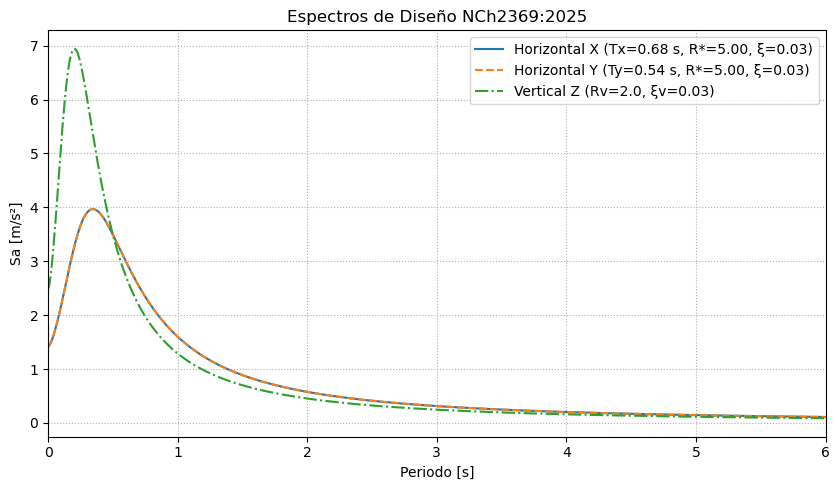

In [9]:
# Salida Sa en [m/s²] para Scale Factor = 1.

import os
import numpy as np
import matplotlib.pyplot as plt

# Carpeta de guardado de espectros
RUTA_SALIDA = r"COPIA AQUI LA RUTA DESEADA PARA GUARDAR LOS ARCHIVOS TXT"

# ==============================================================================
# 1. VARIABLES DE CONFIGURACIÓN GENERAL DEL ESPECTRO SÍSMICO (NCh2369:2025)
# ==============================================================================

# Parámetros dinámicos horizontales X e Y (Tabla 7)
Tx = 0.68                   # Periodo fundamental T* en dirección X [s]
Ty = 0.54                   # Periodo fundamental T* en dirección Y [s]
R = 5.0                     # Factor de modificación de respuesta horizontal (Tabla 7) [-]
xi = 0.03                   # Razón de amortiguamiento horizontal (Tabla 7: 0.02 a 0.05) [-]

# Parámetros dinámicos verticales (Cláusula 5.4)
Rv = 2.0                    # Factor de modificación de respuesta vertical (fijo = 2.0) [-]
xi_v = 0.03                 # Razón de amortiguamiento vertical (por defecto = 0.03) [-]

# Configuración de sitio y categoría
zona_sismica = 3            # Tabla 2 y Tabla 3: 1, 2 o 3
tipo_suelo = "C"            # Tabla 4 y Tabla 6: 'A', 'B', 'C', 'D', 'E'
categoria_ocupacion = "II"  # Tabla 1 y Cláusula 4.3.2: 'I', 'II', 'III', 'IV'
factor_importancia = None   # None usa Cláusula 4.3.2; o valor manual (ej. 1.5)

# Configuración numérica y límites
g = 9.80665                 # Gravedad [m/s²] -> Sa en [m/s²] (Scale Factor = 1)
T_min = 0.00                # Periodo inicial [s]
T_max = 6.00                # Periodo final [s]
dT = 0.01                   # Incremento de periodo [s]
aplicar_limites_Q = False   # True acota Sa horizontal entre Qmín/P y Qmáx/P (5.12 y 5.13)

# Diccionarios normativos NCh2369:2025
parametros_normativos = {
    # Cláusula 4.3.2: Coeficiente de importancia I [-]
    "I": {"I": 0.80, "II": 1.00, "III": 1.20, "IV": 1.20},
    # Tabla 3: Aceleración efectiva máxima A0 y máxima de referencia Ar como fracción de g [-]
    "A0": {1: 0.20, 2: 0.30, 3: 0.40},
    "Ar": {1: 0.28, 2: 0.42, 3: 0.56},
    # Tabla 6: Parámetros según tipo de suelo (S [-], r [-], T0 [s], p [-], q [-], T1 [s])
    "suelos": {
        "A": {"S": 0.90, "r": 4.50, "T0": 0.15, "p": 1.85, "q": 3.00, "T1": 0.15},
        "B": {"S": 1.00, "r": 4.50, "T0": 0.30, "p": 1.60, "q": 3.00, "T1": 0.27},
        "C": {"S": 1.05, "r": 4.50, "T0": 0.40, "p": 1.50, "q": 3.00, "T1": 0.35},
        "D": {"S": 1.00, "r": 3.50, "T0": 0.60, "p": 1.00, "q": 2.50, "T1": 0.41},
        "E": {"S": 1.00, "r": 3.00, "T0": 1.20, "p": 1.00, "q": 2.70, "T1": 0.79},
    }
}

config_exportacion = {"ruta_salida": RUTA_SALIDA,
                      "archivo_x": "Espectro_X_NCh2369.txt",
                      "archivo_y": "Espectro_Y_NCh2369.txt",
                      "archivo_v": "Espectro_Z_NCh2369.txt",
                      "separador": "\t",
                      "dec_T": 4,
                      "dec_Sa": 6}

# ==============================================================================
# 2. CÁLCULO DE ESPECTROS HORIZONTALES (X, Y) Y VERTICAL (Z)
# ==============================================================================

I = factor_importancia or parametros_normativos["I"][categoria_ocupacion]
A0_g = parametros_normativos["A0"][zona_sismica]
Ar_g = parametros_normativos["Ar"][zona_sismica]
Ar = Ar_g * g  # Aceleración máxima de referencia en [m/s²]

s_dat = parametros_normativos["suelos"][tipo_suelo]
S, r, T0, p, q, T1 = s_dat["S"], s_dat["r"], s_dat["T0"], s_dat["p"], s_dat["q"], s_dat["T1"]

# Vector de periodos incluyendo puntos notables exactos (T0, T1, Tx, Ty)
malla_base = np.arange(T_min, T_max + dT / 2, dT)
notables = [t for t in (T0, T1, Tx, Ty) if T_min <= t <= T_max]
T = np.unique(np.round(np.concatenate([malla_base, notables]), 6))

# Ecuación (1b): Factores de reducción R* evaluados en Tx y Ty con un único R [-]
Cr = 0.16 * R
Rx_ast = 1.0 if R == 1.0 else (R if Tx >= Cr * T1 else 1.5 + (R - 1.5) * (Tx / (Cr * T1)))
Ry_ast = 1.0 if R == 1.0 else (R if Ty >= Cr * T1 else 1.5 + (R - 1.5) * (Ty / (Cr * T1)))

# Ecuación (3): Espectro de referencia horizontal SaH(TH) en [m/s²]
SaH = Ar * S * ((1.0 + r * (T / T0) ** p) / (1.0 + (T / T0) ** q))

# Ecuación (1a): Espectros de diseño horizontales Sa_x y Sa_y en [m/s²]
factor_xi_h = (0.05 / xi) ** 0.4
Sa_x = (I * SaH / Rx_ast) * factor_xi_h
Sa_y = (I * SaH / Ry_ast) * factor_xi_h

# Ecuación (4): Espectro de referencia vertical SaV(TV) en [m/s²] (incluye factor 1.7)
SaV = 0.70 * Ar * S * ((1.0 + r * (1.7 * (T / T0)) ** p) / (1.0 + (1.7 * (T / T0)) ** q))

# Ecuación (2): Espectro de diseño vertical Sa_v en [m/s²]
Sa_v = (I * SaV / Rv) * ((0.05 / xi_v) ** 0.4)

# Coeficientes de corte basal mínimo y máximo (Cláusulas 5.12 y 5.13, Ecuaciones 12 y 13)
C_min_g = 0.25 * I * Ar_g * S
C_max_g = (2.75 * I * Ar_g * S / (R + 1.0)) * factor_xi_h if R > 2.0 else None

if aplicar_limites_Q:
    limite_sup = C_max_g * g if C_max_g else None
    Sa_x = np.clip(Sa_x, C_min_g * g, limite_sup)
    Sa_y = np.clip(Sa_y, C_min_g * g, limite_sup)

# ==============================================================================
# 3. EXPORTACIÓN DE ARCHIVOS TXT, RESUMEN Y GRÁFICO
# ==============================================================================

os.makedirs(config_exportacion["ruta_salida"], exist_ok=True)
ruta_x = os.path.join(config_exportacion["ruta_salida"], config_exportacion["archivo_x"])
ruta_y = os.path.join(config_exportacion["ruta_salida"], config_exportacion["archivo_y"])
ruta_v = os.path.join(config_exportacion["ruta_salida"], config_exportacion["archivo_v"])

sep = config_exportacion["separador"]
dec_T, dec_Sa = config_exportacion["dec_T"], config_exportacion["dec_Sa"]

for ruta, sa in [(ruta_x, Sa_x), (ruta_y, Sa_y), (ruta_v, Sa_v)]:
    with open(ruta, "w", encoding="utf-8") as f:
        f.write(f"T(s){sep}Sa\n")
        for t_val, sa_val in zip(T, sa):
            f.write(f"{t_val:.{dec_T}f}{sep}{sa_val:.{dec_Sa}f}\n")

cmax_str = f"{C_max_g:.4f} g" if C_max_g else "No aplica (R <= 2)"

print("=" * 72)
print(" ESPECTRO SÍSMICO — NCh2369:2025")
print("=" * 72)
print(f" Zona Sísmica : {zona_sismica} -> A0 = {A0_g:.2f} g | Ar = {Ar_g:.2f} g ({Ar:.4f} m/s²)")
print(f" Tipo Suelo   : {tipo_suelo} -> S={S}, r={r}, T0={T0} s, p={p}, q={q}, T1={T1} s")
print(f" Categoría    : {categoria_ocupacion} (I = {I:.2f}) | R = {R} | xi = {xi:.2f}")
print(f" Corte Basal  : Q0_mín/P = {C_min_g:.4f} g | Q0_máx/P = {cmax_str}")
print("-" * 72)
print(f" Espectro X   : Tx = {Tx:.3f} s | R*(X) = {Rx_ast:.4f}")
print(f" Espectro Y   : Ty = {Ty:.3f} s | R*(Y) = {Ry_ast:.4f}")
print(f" Espectro Z   : Rv = {Rv:.1f}     | xi_v  = {xi_v:.2f} (Vertical)")
print("=" * 72)

# Despliegue obligatorio del gráfico espectral
plt.figure(figsize=(8.5, 5))
plt.plot(T, Sa_x, label=f"Horizontal X (Tx={Tx} s, R*={Rx_ast:.2f}, ξ={xi})")
plt.plot(T, Sa_y, "--", label=f"Horizontal Y (Ty={Ty} s, R*={Ry_ast:.2f}, ξ={xi})")
plt.plot(T, Sa_v, "-.", label=f"Vertical Z (Rv={Rv}, ξv={xi_v})")
plt.xlabel("Periodo [s]")
plt.ylabel("Sa [m/s²]")
plt.title("Espectros de Diseño NCh2369:2025")
plt.xlim(T_min, T_max)
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()